<a href="https://colab.research.google.com/github/samkenzie/predicting-electrode-transport-properties/blob/main/CNN1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN (Progress Update)

This is a CNN to predict effective conductivity and diffusivity from images. Its results will be compared against two baseline models: the Bruggeman relation and a random forest.

The procedure is as follows:
1. Import image data
2. Import effective diffusivity and conductivity, order it to match image data
3. Train/test/validation split
4. Model implementation
5. Model training (only best model training is shown)
6. Final model
7. GradCAM implementation (heatmaps)

In [2]:
#0. Imports
import numpy as np
from pathlib import Path
import glob
from PIL import Image
from sklearn.model_selection import train_test_split #Using this instead of torch because it is more intuitive to me
import torch.nn as nn
from torch.nn import functional as F
import torch
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [3]:
!unzip -q /content/images_aps360.zip -d /content/images
!unzip -q /content/diffusion_aps360.zip -d /content/texts

In [4]:
#1. Import image data
img_ids, img_pixels = [], []
for path in glob.glob("/content/images/64/*.tif"):
    img_ids.append(int(Path(path).stem)) #123.tif -> 123
    img_pixels.append(np.asarray(Image.open(path)))

img_ids = np.array(img_ids)
img_pixels = np.stack(img_pixels) #Expected (100000, 64, 64)

print(f"Loaded {len(img_ids)} images")
print(f"Array shape {img_pixels.shape}")

Loaded 100000 images
Array shape (100000, 64, 64)


In [5]:
#2. Import effective diffusivity and conductivity data
txt_ids, eff_diff, eff_cond = [], [], []

for path in glob.glob("/content/texts/dispersion/*.txt"):
    with open(path) as fh:
        vals = fh.read().split()
        txt_ids.append(int(Path(path).stem))
        eff_diff.append(float(vals[0]))
        eff_cond.append(float(vals[1]))

print(f"Loaded {len(txt_ids)} text files")

Loaded 100000 text files


In [6]:
#2. CONT... ordering
order = {id_: i for i, id_ in enumerate(txt_ids)}
id = [order[i] for i in img_ids]
eff_diff = np.array(eff_diff)[id]
eff_cond = np.array(eff_cond)[id]

In [7]:
txt_ids_aligned = np.array(txt_ids)[id] #Grabbing .txt IDs

print("img_id  txt_id")
for i in range(10): #Checking if the first 10 image and text file IDs match
    print(f"{img_ids[i]:6d} {txt_ids_aligned[i]:6d}")

print(np.all(img_ids == txt_ids_aligned)) #True if all IDs match

img_id  txt_id
 65225  65225
 97562  97562
 39836  39836
 79837  79837
 40949  40949
 10743  10743
 45504  45504
 99752  99752
 96546  96546
 88132  88132
True


In [8]:
#3. Train/test/validation split
targets = np.stack([eff_diff, eff_cond], axis=1) #Combine arrays, expected (100000, 2)
X_train, X_temp, y_train, y_temp = train_test_split(img_pixels, targets, test_size=0.30, random_state=1) #Split 70/30
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=1) #Splits 30->15/15 for validation and test
print(f"Train: {X_train.shape} {y_train.shape}") #Expected 70000
print(f"Validation: {X_val.shape} {y_val.shape}") #Expected 15000
print(f"Test: {X_test.shape} {y_test.shape}") #Expected 15000

Train: (70000, 64, 64) (70000, 2)
Validation: (15000, 64, 64) (15000, 2)
Test: (15000, 64, 64) (15000, 2)


In [9]:
#4. CNN Implementation
class CNN(nn.Module):
  def __init__(self):
    super(CNN, self).__init__()
    self.name = "cnn"
    #input ... 64x64
    self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
    self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
    self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
    self.conv4 = nn.Conv2d(64, 128, 3, padding=1)
    self.pool = nn.MaxPool2d(2, 2) #4 pools, 64/(2^4)=4
    self.fc1 = nn.Linear(128*4*4, 128)
    self.fc2 = nn.Linear(128, 2)
  def forward(self, x):
    x = self.pool(F.relu(self.conv1(x)))
    x = self.pool(F.relu(self.conv2(x)))
    x = self.pool(F.relu(self.conv3(x)))
    x = self.pool(F.relu(self.conv4(x)))
    x = x.flatten(1)
    x = F.relu(self.fc1(x))
    x = self.fc2(x)
    return x

In [32]:
#5. Model training
def get_metrics(model, data, device, y_mean, y_std):
    model.eval() #Switches NN into evaluation mode
    predictions, targets = [], []

    with torch.no_grad(): #No gradient tracking...
        for imgs, labels in torch.utils.data.DataLoader(data, batch_size=64):
            predictions.append(model(imgs.to(device)).cpu()) #Move to CPU (saves GPU)
            targets.append((labels - y_mean) / y_std) #Normalize targets (because trained on normalized targets)

    model.train()
    p, t = torch.cat(predictions), torch.cat(targets) #One row per sample
    mse = ((p - t) ** 2).mean(0) #Per target value (ie. [eff_diff, eff_cond])
    mae = (p - t).abs().mean(0) #Per target value, standardized units
    r2 = 1 - ((p - t) ** 2).sum(0) / ((t - t.mean(0)) ** 2).sum(0) #Per target value (ie. [eff_diff, eff_cond])
    return mse, mae, r2

def train(model, train_data, val_data, num_epochs, batch_size, lr, device, y_mean, y_std):
    loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True)
    opt = optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    history = {"Train MSE": [], "Validation MSE": [], "Train MAE": [], "Validation MAE": [], "Train R^2": [], "Validation R^2": []}
    y_m, y_s = y_mean.to(device), y_std.to(device) #To GPU

    for epoch in range(num_epochs):
        for imgs, labels in loader:
            imgs = imgs.to(device)
            labels = (labels.to(device) - y_m) / y_s #Normalize targets
            opt.zero_grad(); crit(model(imgs), labels).backward(); opt.step()
        tr_mse, tr_mae, tr_r2 = get_metrics(model, train_data, device, y_mean, y_std)
        val_mse, val_mae, val_r2 = get_metrics(model, val_data, device, y_mean, y_std)
        history["Train MSE"].append(tr_mse.mean().item())
        history["Validation MSE"].append(val_mse.mean().item())
        history["Train MAE"].append(tr_mae.mean().item())
        history["Validation MAE"].append(val_mae.mean().item())
        history["Train R^2"].append(tr_r2.tolist())
        history["Validation R^2"].append(val_r2.tolist())
        print(f"Epoch {epoch+1}: \nValidation MSE = {val_mse.mean():.4f} \nValidation MAE = {val_mae.mean():.4f} \nValidation R^2 Eff. Diff. = {val_r2[0]:.3f}, Eff. Cond = {val_r2[1]:.3f}")

    return history

In [29]:
#To improve training speed on Mac...
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cuda


In [33]:
#Conversion to tensor
X_train_torch = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1) /255.0 #255.0 to scale 0->1, unsqueeze(1) for 1 channel dimension (black)
y_train_torch = torch.tensor(y_train, dtype=torch.float32)
X_val_torch = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1) / 255.0
y_val_torch = torch.tensor(y_val, dtype=torch.float32)

train_set = TensorDataset(X_train_torch, y_train_torch) #Merge into single tensor
val_set = TensorDataset(X_val_torch, y_val_torch) #Merge into single tensor

y_mean = y_train_torch.mean(0)
y_std = y_train_torch.std(0)

Code below is for the training of the best CNN after hyperparameter tuning (number of layers, pooling, batch size, learning rate) - other CNNs were discarded.

In [34]:
model = CNN().to(device)
hist = train(model, train_set, val_set, num_epochs=20, batch_size=128, lr=1e-3, device=device, y_mean=y_mean, y_std=y_std)

Epoch 1: 
Validation MSE = 0.0509 
Validation MAE = 0.1760 
Validation R^2 Eff. Diff. = 0.946, Eff. Cond = 0.951
Epoch 2: 
Validation MSE = 0.0448 
Validation MAE = 0.1687 
Validation R^2 Eff. Diff. = 0.947, Eff. Cond = 0.963
Epoch 3: 
Validation MSE = 0.0315 
Validation MAE = 0.1373 
Validation R^2 Eff. Diff. = 0.970, Eff. Cond = 0.966
Epoch 4: 
Validation MSE = 0.0285 
Validation MAE = 0.1291 
Validation R^2 Eff. Diff. = 0.975, Eff. Cond = 0.968
Epoch 5: 
Validation MSE = 0.0348 
Validation MAE = 0.1422 
Validation R^2 Eff. Diff. = 0.960, Eff. Cond = 0.969
Epoch 6: 
Validation MSE = 0.0276 
Validation MAE = 0.1279 
Validation R^2 Eff. Diff. = 0.973, Eff. Cond = 0.971
Epoch 7: 
Validation MSE = 0.0283 
Validation MAE = 0.1308 
Validation R^2 Eff. Diff. = 0.971, Eff. Cond = 0.972
Epoch 8: 
Validation MSE = 0.0248 
Validation MAE = 0.1219 
Validation R^2 Eff. Diff. = 0.977, Eff. Cond = 0.973
Epoch 9: 
Validation MSE = 0.0214 
Validation MAE = 0.1118 
Validation R^2 Eff. Diff. = 0.978, E

In [40]:
#Checking training vs. validation gap
print(f"Train MSE {hist["Train MSE"][-1]:.4f}, Validation MSE {hist["Validation MSE"][-1]:.4f}")
print(f"Train RMSE {hist['Train MSE'][-1]**0.5:.4f}, Validation RMSE {hist['Validation MSE'][-1]**0.5:.4f}")
print(f"Train MAE {hist["Train MAE"][-1]:.4f}, Validation MAE {hist["Validation MAE"][-1]:.4f}")

Train MSE 0.0109, Validation MSE 0.0146
Train RMSE 0.1046, Validation RMSE 0.1210
Train MAE 0.0804, Validation MAE 0.0920


Relatively small training vs. validation gap, thus minimal overfitting! Added RMSE to check difference between it and MAE.

In [41]:
X_test_torch = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1) / 255.0
y_test_torch = torch.tensor(y_test, dtype=torch.float32)
test_set = TensorDataset(X_test_torch, y_test_torch)

In [44]:
test_mse, test_mae, test_R2 = get_metrics(model, test_set, device, y_mean, y_std)
print("Test MSE = {test_mse:.4f} \nTest MAE = {test_mae:.4f} \nTest R^2 Eff. Diff. = {test_r2[0]:.3f}, Eff. Cond. = {test_r2[1]:.3f}".format(test_mse=test_mse.mean(), test_mae=test_mae.mean(), test_r2=test_R2))

Test MSE = 0.0147 
Test MAE = 0.0922 
Test R^2 Eff. Diff. = 0.984, Eff. Cond. = 0.986


Inspired by/help from (proper citations in progress report):
1. https://medium.com/the-owl/gradcam-in-pytorch-7b700caa79e5
2. https://openaccess.thecvf.com/content_ICCV_2017/papers/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.pdf
3. https://jss367.github.io/model-explainability-with-grad-cam-in-pytorch.html

In [45]:
def gradcam(model, x, target_id, layer=3): #On third convolutional layer...
#Fourth layer had resolution too low to produce meaningful maps
    model.eval() #Switches NN into evaluation mode
    current, activations = x, None #current = current image going through model, activations = feature maps retained

    for i, conv in enumerate([model.conv1, model.conv2, model.conv3, model.conv4], 1): #Moves through layers, keeps only for layer 3
        current = F.relu(conv(current)) #conv() finds patterns, relu() keeps them
        if i == layer: #If at third layer
            current.retain_grad() #Keeps gradients
            activations = current
        current = model.pool(current) #Pool then continue to next layer

    out = model.fc2(F.relu(model.fc1(current.flatten(1)))) #Finish forward pass
    model.zero_grad() #Remove saved gradients
    out[0, target_id].backward() #Backward pass

    weights = activations.grad.mean(dim=(2, 3), keepdim=True) #Importance per channel (for height and width (image dimensions are (num, channels, height, width)))
    heatmap = F.relu((weights * activations).sum(1, keepdim=True)) #Sum of multiplying channel (of dim=1 since black and white) by weight
    heatmap = F.interpolate(heatmap, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0] #Stretches back to 64x64 (https://docs.pytorch.org/docs/2.15/generated/torch.nn.functional.interpolate.html)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8) #Mapping from 0-1 (1e-8 to avoid division by 0)
    return heatmap.detach().cpu().numpy() #To CPU for numpy, to numpy for plotting

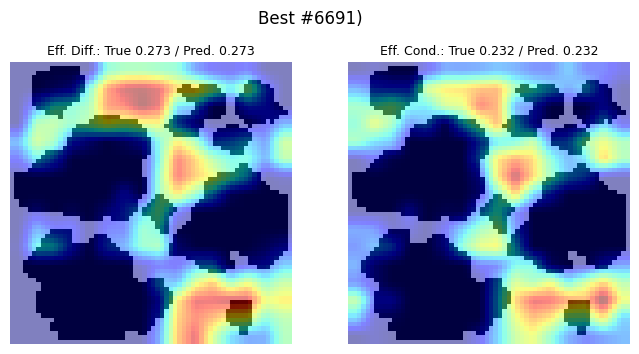

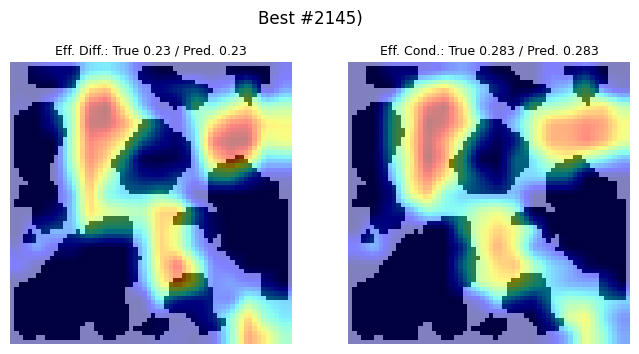

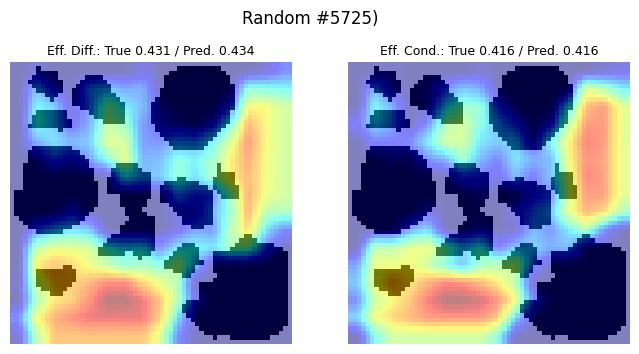

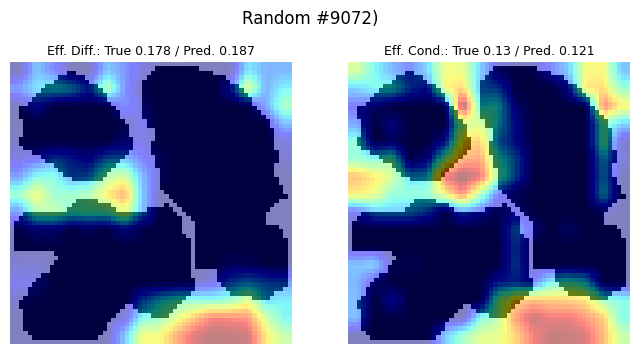

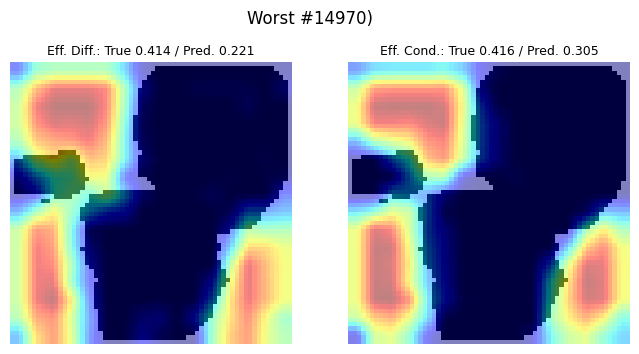

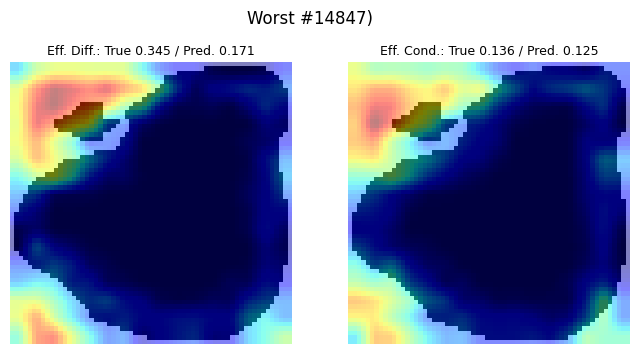

In [46]:
model.eval() #Switch NN to evaluation mode
with torch.no_grad(): #Don't track gradients
    chunks = []
    for start in range(0, len(X_test_torch), 1024): #For chunks of 1024 samples
        batch = X_test_torch[start:start + 1024].to(device) #Create a batch
        chunks.append(model(batch).cpu()) #Add the batch predictions to chunks list
    pred_norm = torch.cat(chunks) #Normalized prediction, one row per image

y_test_norm = (y_test_torch - y_mean) / y_std #Normalize targets
err = ((pred_norm - y_test_norm) ** 2).mean(dim=1) #Average error over targets
order = err.argsort() #Sort error
rand = torch.randperm(len(err))[:2] #Pick to random indices

picks = [("Best", order[0]),   ("Best", order[1]), #Best 2
         ("Random", rand[0]),  ("Random", rand[1]), #Random 2
         ("Worst", order[-1]), ("Worst", order[-2])] #Worst 2

#Plotting: diffusivity heatmap, conductivity heatmap
for tag, i in picks: #tag = "Best", "Random", "Worst"
    i = int(i) #Tensor index to int
    x = X_test_torch[i:i+1].to(device)
    true = y_test_torch[i] #Target value
    pred = pred_norm[i] * y_std + y_mean #Prediction back to real units

    fig, axs = plt.subplots(1, 2, figsize=(8, 4))
    fig.suptitle(f"{tag} #{i})")
    for col, name in enumerate(["Eff. Diff.", "Eff. Cond."]):
        axs[col].imshow(x[0, 0].cpu(), cmap="gray") #Bottom layer (image)
        axs[col].imshow(gradcam(model, x, target_id=col), cmap="jet", alpha=0.5) #Overlay heatmap
        axs[col].set_title(f"{name}: True {true[col]:.3g} / Pred. {pred[col]:.3g}", fontsize=9)
        axs[col].axis("off")
    plt.show()